# Next quarter's industry funding rate

A funding desk that only sees the Call Report wants next quarter's annualized interest-expense rate for all insured US banks. The rate is built from interest expense on all interest-bearing liabilities. `interest_expense_qtr` is interest on every interest-bearing liability, deposits and borrowings together, and the quarterly aggregate does not separate them. The annualized rate used here is the one the loader documents: `400 * interest_expense_qtr / deposits`.

The file is `mb.datasets.bank_funding`, quarterly totals from the FDIC (Federal Deposit Insurance Corporation) BankFind financials API, index `risview_20260608210616`. Dollar amounts are in thousands. The series runs from 1992Q1 through 2026Q1. This page does not refresh it.

The decision is which working distribution to put on a forecast that may only use last quarter's Call Report. A log-link gamma is the usual reflex for a positive rate. A Gaussian, a Student-t, and that gamma are scored on 2020Q1–2026Q1, which includes the drop to the floor and the 2022–2023 rise. Steps for the boosting fits are chosen on 2016–2019 only.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | next quarter's annualized interest-expense rate, all insured banks |
| **Observed response** | `400 * interest_expense_qtr / deposits`, percent |
| **Estimand** | held-out mean absolute error, and the mean negative log density of that rate |
| **Units** | percentage points; nats per quarter |
| **Sampling unit** | one row is one quarterly aggregate for insured US banks |
| **Dependence** | Quarters are serially related; ordered periods are used rather than random quarter folds. |
| **Split and tuning** | fit through 2019Q4; choose boosting steps on 2016–2019; score 2020Q1–2026Q1 |
| **Information** | lagged rate, lagged deposit growth, lagged asset growth |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | the rate paid on deposits alone, a bank-level marginal cost, or a causal effect of policy |

:::


In [1]:
import io
import warnings
from contextlib import redirect_stdout

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.miscmodels.tmodel import TLinearModel

import mboostrs as mb

raw = mb.datasets.bank_funding(output="polars").sort("repdte")
frame = raw.with_columns(
    (400.0 * pl.col("interest_expense_qtr") / pl.col("deposits")).alias("rate"),
    (pl.col("deposits") / pl.col("deposits").shift(1) - 1).alias("dep_g"),
    (pl.col("assets") / pl.col("assets").shift(1) - 1).alias("asset_g"),
).with_columns(
    pl.col("rate").shift(1).alias("rate_l1"),
    pl.col("dep_g").shift(1).alias("dep_g_l1"),
    pl.col("asset_g").shift(1).alias("asset_g_l1"),
).drop_nulls(["rate_l1", "dep_g_l1", "asset_g_l1"])

early = frame.filter(pl.col("repdte") < "2016-01-01")
valid = frame.filter((pl.col("repdte") >= "2016-01-01") & (pl.col("repdte") < "2020-01-01"))
train = frame.filter(pl.col("repdte") < "2020-01-01")
test = frame.filter(pl.col("repdte") >= "2020-01-01")
hike = (test["repdte"] >= "2022-01-01").to_numpy()
formula = "rate ~ rate_l1 + dep_g_l1 + asset_g_l1"
columns = ["rate_l1", "dep_g_l1", "asset_g_l1"]
print(
    f"{frame.height} quarters, {early.height} before 2016, {valid.height} in 2016-19, "
    f"{train.height} through 2019, {test.height} from 2020, {int(hike.sum())} from 2022"
)


135 quarters, 94 before 2016, 16 in 2016-19, 110 through 2019, 25 from 2020, 17 from 2022


In [2]:
def design(data):
    return sm.add_constant(data.select(columns).to_numpy())


y_train = train["rate"].to_numpy()
y_test = test["rate"].to_numpy()
x_train, x_test = design(train), design(test)

ols = sm.OLS(y_train, x_train).fit()
ols_mu = np.asarray(ols.predict(x_test), dtype=float)
ols_sd = float(np.sqrt(np.mean((y_train - ols.fittedvalues) ** 2)))

gamma = sm.GLM(y_train, x_train, family=sm.families.Gamma(sm.families.links.Log())).fit()
gamma_mu = np.asarray(gamma.predict(x_test), dtype=float)
gamma_shape = 1.0 / float(gamma.scale)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with redirect_stdout(io.StringIO()):
        t_model = TLinearModel(y_train, x_train).fit(method="bfgs", disp=False, maxiter=400)
t_mu = np.asarray(t_model.predict(x_test), dtype=float)
t_df = float(t_model.params[-2])
t_scale = abs(float(t_model.params[-1]))
t_converged = bool(t_model.mle_retvals.get("converged"))


In [3]:
def validation_objective(kind, pred, y_valid, train_sd=None):
    y_valid = np.asarray(y_valid, dtype=float)
    if kind == "mae":
        return float(np.mean(np.abs(np.asarray(pred).ravel() - y_valid)))
    if kind == "gaussian":
        return float(-stats.norm.logpdf(y_valid, np.asarray(pred).ravel(), train_sd).mean())
    if kind == "t":
        return float(-stats.t.logpdf(
            y_valid, np.asarray(pred["df"]), loc=np.asarray(pred["mu"]), scale=np.asarray(pred["sigma"])
        ).mean())
    raise ValueError(kind)


def choose_mstop(ctor, family, kind, cap, location_scale):
    kwargs = {"family": family, "control": mb.boost_control(cap, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    path = ctor(formula, early, **kwargs)
    y_valid = valid["rate"].to_numpy()
    best_step, best_score = None, np.inf
    for step in range(20, cap + 1, 10):
        tuned = path.with_mstop([step] if location_scale else step)
        pred = tuned.predict(valid, type="response")
        if kind == "gaussian":
            train_mu = np.asarray(tuned.predict(early, type="response"), dtype=float).ravel()
            train_sd = float(np.sqrt(np.mean((early["rate"].to_numpy() - train_mu) ** 2)))
            score = validation_objective(kind, pred, y_valid, train_sd)
        else:
            score = validation_objective(kind, pred, y_valid)
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap


jobs = [
    ("mboostrs glmboost Gaussian", mb.glmboost, mb.Gaussian(), "gaussian", 400, False),
    ("mboostrs glmboost GammaReg", mb.glmboost, mb.GammaReg(), "mae", 400, False),
    ("mboostrs glmboostLSS StudentTLSS", mb.glmboostLSS, mb.StudentTLSS(), "t", 600, True),
]
boosted = {}
for label, ctor, family, kind, cap, location_scale in jobs:
    step, score, at_cap = choose_mstop(ctor, family, kind, cap, location_scale)
    kwargs = {"family": family, "control": mb.boost_control(step, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    fit = ctor(formula, train, **kwargs)
    boosted[label] = {
        "mstop": step,
        "validation": score,
        "at_cap": at_cap,
        "fit": fit,
        "pred": fit.predict(test, type="response"),
        "kind": kind,
    }


In [4]:
def gaussian_nll(y, mu, sd):
    return float(-stats.norm.logpdf(y, mu, sd).mean())


def gamma_nll(y, mu, shape):
    mu = np.clip(np.asarray(mu, dtype=float), 1e-8, None)
    return float(-stats.gamma.logpdf(y, a=shape, scale=mu / shape).mean())


def t_nll(y, mu, scale, df):
    return float(-stats.t.logpdf(y, df, loc=mu, scale=scale).mean())


rows = []


def add(method, mu, nll, hike_nll, mstop=None, at_cap=None, note=""):
    mu = np.asarray(mu, dtype=float)
    rows.append({
        "method": method,
        "mae": float(np.mean(np.abs(mu - y_test))),
        "hike_mae": float(np.mean(np.abs(mu[hike] - y_test[hike]))),
        "hike_bias": float(np.mean(mu[hike] - y_test[hike])),
        "nll": nll,
        "hike_nll": hike_nll,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add(
    "statsmodels OLS",
    ols_mu,
    gaussian_nll(y_test, ols_mu, ols_sd),
    gaussian_nll(y_test[hike], ols_mu[hike], ols_sd),
    note=f"residual sd {ols_sd:.3f}",
)
add(
    "statsmodels Gamma GLM",
    gamma_mu,
    gamma_nll(y_test, gamma_mu, gamma_shape),
    gamma_nll(y_test[hike], gamma_mu[hike], gamma_shape),
    note=f"shape {gamma_shape:.2f}",
)
add(
    "statsmodels TLinearModel",
    t_mu,
    t_nll(y_test, t_mu, t_scale, t_df),
    t_nll(y_test[hike], t_mu[hike], t_scale, t_df),
    note=f"df {t_df:.2f}, scale {t_scale:.3f}, converged {t_converged}",
)
for label, item in boosted.items():
    kind, pred, fit = item["kind"], item["pred"], item["fit"]
    if kind == "t":
        mu = np.asarray(pred["mu"], dtype=float).ravel()
        sigma = np.asarray(pred["sigma"], dtype=float).ravel()
        df_hat = np.asarray(pred["df"], dtype=float).ravel()
        nll = t_nll(y_test, mu, sigma, df_hat)
        hike_nll = t_nll(y_test[hike], mu[hike], sigma[hike], df_hat[hike])
        note = f"mean sigma {float(sigma.mean()):.3f}, mean df {float(df_hat.mean()):.1f}"
        student_df = float(df_hat.mean())
    elif kind == "gaussian":
        mu = np.asarray(pred, dtype=float).ravel()
        train_mu = np.asarray(fit.predict(train, type="response"), dtype=float).ravel()
        sd = float(np.sqrt(np.mean((y_train - train_mu) ** 2)))
        nll = gaussian_nll(y_test, mu, sd)
        hike_nll = gaussian_nll(y_test[hike], mu[hike], sd)
        note = f"residual sd {sd:.3f}"
    else:
        mu = np.asarray(pred, dtype=float).ravel()
        shape = float(np.asarray(fit.nuisance()).ravel()[0])
        nll = gamma_nll(y_test, mu, shape)
        hike_nll = gamma_nll(y_test[hike], mu[hike], shape)
        note = f"shape {shape:.2f}"
        gamma_boost_shape = shape
    add(label, mu, nll, hike_nll, item["mstop"], item["at_cap"], note)

summary = pl.DataFrame(rows).sort("nll")
display(summary)


method,mae,hike_mae,hike_bias,nll,hike_nll,mstop,at_cap,note
str,f64,f64,f64,f64,f64,i64,bool,str
"""mboostrs glmboost Gaussian""",0.202277,0.229132,-0.141939,0.073476,0.18257,40,false,"""residual sd 0.263"""
"""statsmodels OLS""",0.232013,0.261559,-0.179392,0.28479,0.401568,null,null,"""residual sd 0.259"""
"""statsmodels TLinearModel""",0.229303,0.252195,-0.157238,0.288002,0.439455,null,null,"""df 2.13, scale 0.140, converge…"
"""statsmodels Gamma GLM""",0.625157,0.727275,-0.637973,2.533203,2.171851,null,null,"""shape 13.60"""
"""mboostrs glmboost GammaReg""",0.626116,0.727371,-0.637713,2.610379,2.215373,20,false,"""shape 13.96"""
"""mboostrs glmboostLSS StudentTL…",0.195357,0.25216,-0.18807,3.384921,5.38909,140,false,"""mean sigma 0.159, mean df 1535…"


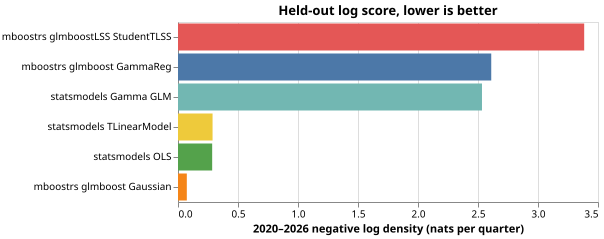

In [5]:
alt.Chart(summary).mark_bar().encode(
    x=alt.X("nll:Q", title="2020–2026 negative log density (nats per quarter)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=420,
    height=180,
    title="Held-out log score, lower is better",
)


## Results and interpretation

The rate is a persistent level. OLS puts a coefficient of {eval}`f"{float(ols.params[1]):.2f}"` on last quarter's rate. On 2020Q1–2026Q1 the Gaussian forecasts have mean absolute errors of {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['mae'][0]):.3f}"` (OLS) and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['mae'][0]):.3f}"` (boosted Gaussian, {eval}`str(int(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['mstop'][0]))` steps). The log-link gamma fits, statsmodels and `GammaReg`, are about {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Gamma GLM')['mae'][0]):.2f}"` and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost GammaReg')['mae'][0]):.2f}"` percentage points off. The log link makes covariate effects multiplicative: the same change in the
linear predictor produces a larger absolute rate change from 2 than from 0.3.
That specification predicts the drop and subsequent rise less accurately here. Their log scores are {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Gamma GLM')['nll'][0]):.2f}"` and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost GammaReg')['nll'][0]):.2f}"` nats per quarter, against {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['nll'][0]):.3f}"` for the short Gaussian boost and {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['nll'][0]):.3f}"` for OLS.

The Student-t maximum likelihood fit converged with df {eval}`f"{t_df:.2f}"` and scale {eval}`f"{t_scale:.3f}"`. A Student-t distribution has no finite variance when df is at most 2;
just above 2, its variance is finite but can be very large. Its holdout log score is {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels TLinearModel')['nll'][0]):.3f}"`, no better than the Gaussian. The boosted t, with steps chosen by log score on the 2016–2019 window, is worse: mean df {eval}`f"{student_df:.0f}"` and a holdout log score of {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS StudentTLSS')['nll'][0]):.2f}"`. That window rewards a very tight distribution. The 2022–2026 rise does not fit inside it.

From 2022Q1 on, the errors in the hike window (the 2022–2023 rise in the rate; forecast minus actual) are {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['hike_bias'][0]):.2f}"` for OLS and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['hike_bias'][0]):.2f}"` for the boosted Gaussian. Negative means the forecast sat below the rate that was paid.

Publish the short Gaussian boost, or OLS if the only requirement is a closed form. Do not switch the rate forecast to a log-link gamma. Do not publish the t whose degrees of freedom were chosen on 2016–2019. The number is the annualized interest on all interest-bearing liabilities, divided by deposits.


In [6]:
probe = boosted["mboostrs glmboost GammaReg"]["fit"]
link = np.asarray(probe.predict(type="link"), dtype=float)
response = np.asarray(probe.predict(type="response"), dtype=float)
gamma_link_gap = float(np.max(np.abs(np.exp(link) - response)))
gamma_shape_fit = float(np.asarray(probe.nuisance()).ravel()[0])
train_mu = np.asarray(probe.predict(train, type="response"), dtype=float)
scipy_ll = float(stats.gamma.logpdf(y_train, a=gamma_shape_fit, scale=np.clip(train_mu, 1e-8, None) / gamma_shape_fit).sum())
gamma_ll_gap = abs(float(probe.logLik()) - scipy_ll)
student = boosted["mboostrs glmboostLSS StudentTLSS"]["fit"]
try:
    mb.glmboost(formula, train, family=mb.StudentTLSS(), control=mb.boost_control(5, 0.1))
    glmboost_student = "accepted"
except Exception as exc:
    glmboost_student = str(exc).split("\n")[0]
print("gamma link matches exp(response) gap", gamma_link_gap)
print("gamma logLik gap", gamma_ll_gap, "shape", gamma_shape_fit)
print("student offset", student.offset)
print("student response df", float(np.mean(student.predict(type="response")["df"])))
print("glmboost StudentTLSS:", glmboost_student)


gamma link matches exp(response) gap 0.0
gamma logLik gap 4.263256414560601e-14 shape 13.958477530770555
student offset {'mu': 2.5925824695960613, 'sigma': 0.5882054707299045, 'df': 16.54693589077307}
student response df 15354757.069177069
glmboost StudentTLSS: StudentTLSS is a distributional family (parameters: mu, sigma, df). glmboost() fits one predictor. Use glmboostLSS() or gamboostLSS(), for example mb.gamboostLSS(formula, data, family=mb.StudentTLSS()).


## API behavior and limitations

`GammaReg` `predict` with no `type` is the log mean. `type="response"` is the mean, and it matches `exp` of the link (the probe gap is numerical zero). The scores above use `type="response"`. `nuisance()` on this fit is the gamma shape, {eval}`f"{gamma_shape_fit:.2f}"`, not a variance. `logLik()` matches a gamma density with that shape and the fitted means, to {eval}`f"{gamma_ll_gap:.1e}"`.

`StudentTLSS` `offset["df"]` is a log degrees of freedom, {eval}`f"{float(student.offset['df']):.2f}"`, not the df itself. The fitted response-scale df on the training sample is very large; the mean df in "Results and interpretation" gives its value. Use `predict(type="response")["df"]` to read fitted degrees of freedom.
The 2016–2019 tuning score alone does not establish interval calibration
during the later rate increases.

`glmboost(family=StudentTLSS())` still says the family is unknown. This is a limitation of that call. The t fit on this page is `glmboostLSS`.

`TLinearModel` prints `running Tmodel initialize` during `fit`. The cell redirects it. Its df below 3 is a fitted result, not a failure to converge: the fit reports converged.
